# 결함 이벤트 시작 전 6~24시간 패턴 분석

이 노트북은 실시간 전처리 데이터를 이용해 결함 발생 **이전**에 관측 가능한 전조가 있는지 탐색합니다. 결함 시작 시각을 0으로 맞춘 이벤트 정렬(event alignment)을 사용합니다.

분석 질문은 다음과 같습니다.

1. 결함 발생 24~12시간 전과 마지막 6시간의 센서 수준이 달라지는가?
2. 마지막 6시간에 센서 변동성이 커지는가?
3. 60분 이동평균에서 일관된 상승·하락 추세가 나타나는가?
4. 이러한 패턴이 결함 유형별 여러 이벤트에서 반복되는가?

모든 특징은 해당 시점까지의 값만 사용하는 방식으로 계산합니다. `fault_type`, `efficiency_loss_pct`, `time_to_fault_min`은 입력 특징에 사용하지 않습니다.


## 0. 데이터와 분석 변수

실시간 전처리 파일은 반응기별 과거 값만 최대 6분 유지한 데이터입니다. 원래 결측 여부 플래그는 데이터에 남아 있지만, 이번 노트북은 공정 센서의 사전 변화에 집중합니다.


In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message="FigureCanvasAgg is non-interactive.*")
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 190)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({
    "figure.figsize": (12, 5), "font.family": "Nanum Gothic",
    "axes.unicode_minus": False, "axes.titlesize": 12, "font.size": 9,
})

DATA_PATH = Path("data/processed/chemical_process_timeseries_realtime_ffill.csv.gz")
if not DATA_PATH.exists():
    DATA_PATH = Path("../data/processed/chemical_process_timeseries_realtime_ffill.csv.gz")

sensor_cols = [
    "reactor_temp", "reactor_pressure", "feed_flow_rate", "coolant_flow_rate",
    "agitator_speed_rpm", "reaction_rate", "conversion_rate", "selectivity",
    "yield_pct", "vibration_rms", "motor_current", "power_consumption_kw",
]
use_cols = ["timestamp", "operating_regime", "reactor_id", "fault_type"] + sensor_cols

df = pd.read_csv(DATA_PATH, usecols=use_cols, parse_dates=["timestamp"])
df = df.sort_values(["reactor_id", "timestamp"]).reset_index(drop=True)

fault_names = {
    1: "F1 냉각 성능 저하", 2: "F2 원료 유량 막힘",
    3: "F3 센서 드리프트", 4: "F4 기계 마모",
}

print(f"분석 데이터: {len(df):,}행")
print(f"분석 센서: {len(sensor_cols)}개")
print(f"기간: {df['timestamp'].min()} ~ {df['timestamp'].max()}")


분석 데이터: 777,600행
분석 센서: 12개
기간: 2024-01-01 00:00:00 ~ 2024-03-30 23:59:00


## 1. 결함 이벤트 정의와 사전 구간 품질 검사

같은 반응기에서 `fault_type`이 0에서 1~4로 바뀌는 첫 시점을 결함 시작으로 정의합니다. 다음 조건을 모두 만족하는 이벤트만 사전 패턴 집계에 사용합니다.

- 시작 전 24시간인 1,440개 관측치가 모두 존재
- 시작 전 24시간의 `fault_type`이 모두 정상(0)

이 기준은 이전 결함의 회복 구간을 새로운 결함의 전조로 잘못 해석하는 것을 막습니다.


             total_events  eligible_events  median_duration_min
fault_name                                                     
F1 냉각 성능 저하            10                8              953.500
F2 원료 유량 막힘             9                9              841.000
F3 센서 드리프트              7                7              559.000
F4 기계 마모                9                9              672.000

제외된 이벤트
 event_id reactor_id               start  fault_name  pre_rows  prior_fault_rows
       16       B_R1 2024-01-01 05:19:00 F1 냉각 성능 저하       319                 0
       18       B_R1 2024-01-08 00:22:00 F1 냉각 성능 저하      1440               202


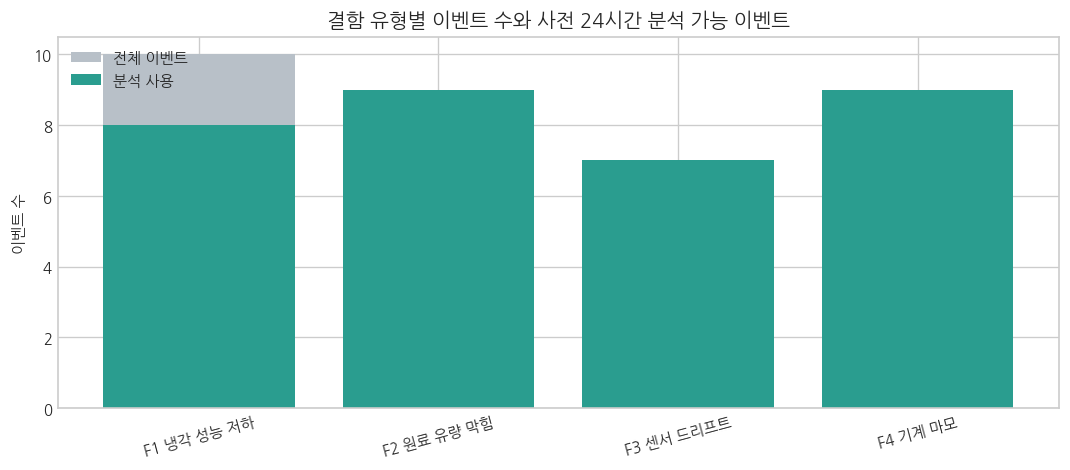

In [2]:
df["segment_start"] = df.groupby("reactor_id")["fault_type"].transform(lambda s: s.ne(s.shift()))
df["segment_id"] = df.groupby("reactor_id")["segment_start"].cumsum()

segments = (df.groupby(["reactor_id", "segment_id"], as_index=False)
            .agg(start=("timestamp", "min"), end=("timestamp", "max"),
                 fault_type=("fault_type", "first"),
                 operating_regime=("operating_regime", "first"),
                 duration_min=("timestamp", "size")))
events = segments[segments["fault_type"].ne(0)].copy().reset_index(drop=True)
events["event_id"] = np.arange(1, len(events) + 1)

quality_rows = []
for event in events.itertuples():
    reactor = df[df["reactor_id"].eq(event.reactor_id)]
    pre = reactor[
        reactor["timestamp"].ge(event.start - pd.Timedelta(hours=24))
        & reactor["timestamp"].lt(event.start)
    ]
    quality_rows.append({
        "event_id": event.event_id,
        "pre_rows": len(pre),
        "prior_fault_rows": int(pre["fault_type"].ne(0).sum()),
        "has_full_24h": len(pre) == 1440,
        "clean_pre_window": len(pre) == 1440 and pre["fault_type"].eq(0).all(),
    })

event_quality = events.merge(pd.DataFrame(quality_rows), on="event_id")
event_quality["fault_name"] = event_quality["fault_type"].map(fault_names)
eligible_events = event_quality[event_quality["clean_pre_window"]].copy()

event_summary = event_quality.groupby("fault_name").agg(
    total_events=("event_id", "count"),
    eligible_events=("clean_pre_window", "sum"),
    median_duration_min=("duration_min", "median"),
)
print(event_summary.to_string())
print("\n제외된 이벤트")
print(event_quality.loc[~event_quality["clean_pre_window"], [
    "event_id", "reactor_id", "start", "fault_name", "pre_rows", "prior_fault_rows"
]].to_string(index=False))

fig, ax = plt.subplots(figsize=(9, 4))
x = np.arange(len(event_summary))
ax.bar(x, event_summary["total_events"], label="전체 이벤트", color="#b8c0c8")
ax.bar(x, event_summary["eligible_events"], label="분석 사용", color="#2a9d8f")
ax.set_xticks(x, event_summary.index, rotation=15)
ax.set_ylabel("이벤트 수")
ax.set_title("결함 유형별 이벤트 수와 사전 24시간 분석 가능 이벤트")
ax.legend()
plt.tight_layout()
plt.show()


## 2. 이벤트 정렬과 기준 구간

각 이벤트의 시작 시각을 0분으로 맞추고 이전 24시간을 모읍니다.

- **기준 구간:** 시작 24~12시간 전
- **중간 구간:** 시작 12~6시간 전
- **최근 구간:** 시작 6시간 전부터 직전 1분까지

센서마다 단위가 다르므로 각 이벤트의 기준 구간 중앙값과 IQR을 이용해 표준화합니다.

`표준화 값 = (관측값 - 기준 구간 중앙값) / 기준 구간 IQR`

0에 가까우면 기준 구간과 비슷하고, 절댓값 1은 기준 구간의 사분위 범위만큼 변했다는 뜻입니다.


In [3]:
windows = []
baseline_rows = []

for event in eligible_events.itertuples():
    pre = df[
        df["reactor_id"].eq(event.reactor_id)
        & df["timestamp"].ge(event.start - pd.Timedelta(hours=24))
        & df["timestamp"].lt(event.start)
    ].copy()
    pre["event_id"] = event.event_id
    pre["event_start"] = event.start
    pre["event_fault_type"] = event.fault_type
    pre["relative_min"] = (pre["timestamp"] - event.start).dt.total_seconds().div(60).astype(int)

    base = pre[pre["relative_min"].lt(-720)]
    med = base[sensor_cols].median()
    iqr = base[sensor_cols].quantile(.75) - base[sensor_cols].quantile(.25)
    iqr = iqr.replace(0, np.nan)
    pre[[f"{c}__norm" for c in sensor_cols]] = (pre[sensor_cols] - med) / iqr

    baseline_rows.append(pd.DataFrame({
        "event_id": event.event_id, "sensor": sensor_cols,
        "baseline_median": med.values, "baseline_iqr": iqr.values,
    }))
    windows.append(pre)

pre_windows = pd.concat(windows, ignore_index=True)
event_baselines = pd.concat(baseline_rows, ignore_index=True)

print(f"사용 이벤트: {eligible_events.shape[0]}개")
print(f"사전 구간 행 수: {len(pre_windows):,}개")
print(f"이벤트당 관측 수: {pre_windows.groupby('event_id').size().min()} ~ {pre_windows.groupby('event_id').size().max()}")
print(f"분석 구간: {pre_windows['relative_min'].min()} ~ {pre_windows['relative_min'].max()}분")


사용 이벤트: 33개
사전 구간 행 수: 47,520개
이벤트당 관측 수: 1440 ~ 1440
분석 구간: -1440 ~ -1분


## 3. 결함 유형별 센서 궤적

30분 단위로 요약한 표준화 센서값의 중앙값을 선으로, 이벤트 간 25~75% 범위를 음영으로 표시합니다. 음영이 넓으면 같은 결함 유형 안에서도 이벤트별 패턴이 일관되지 않다는 뜻입니다.


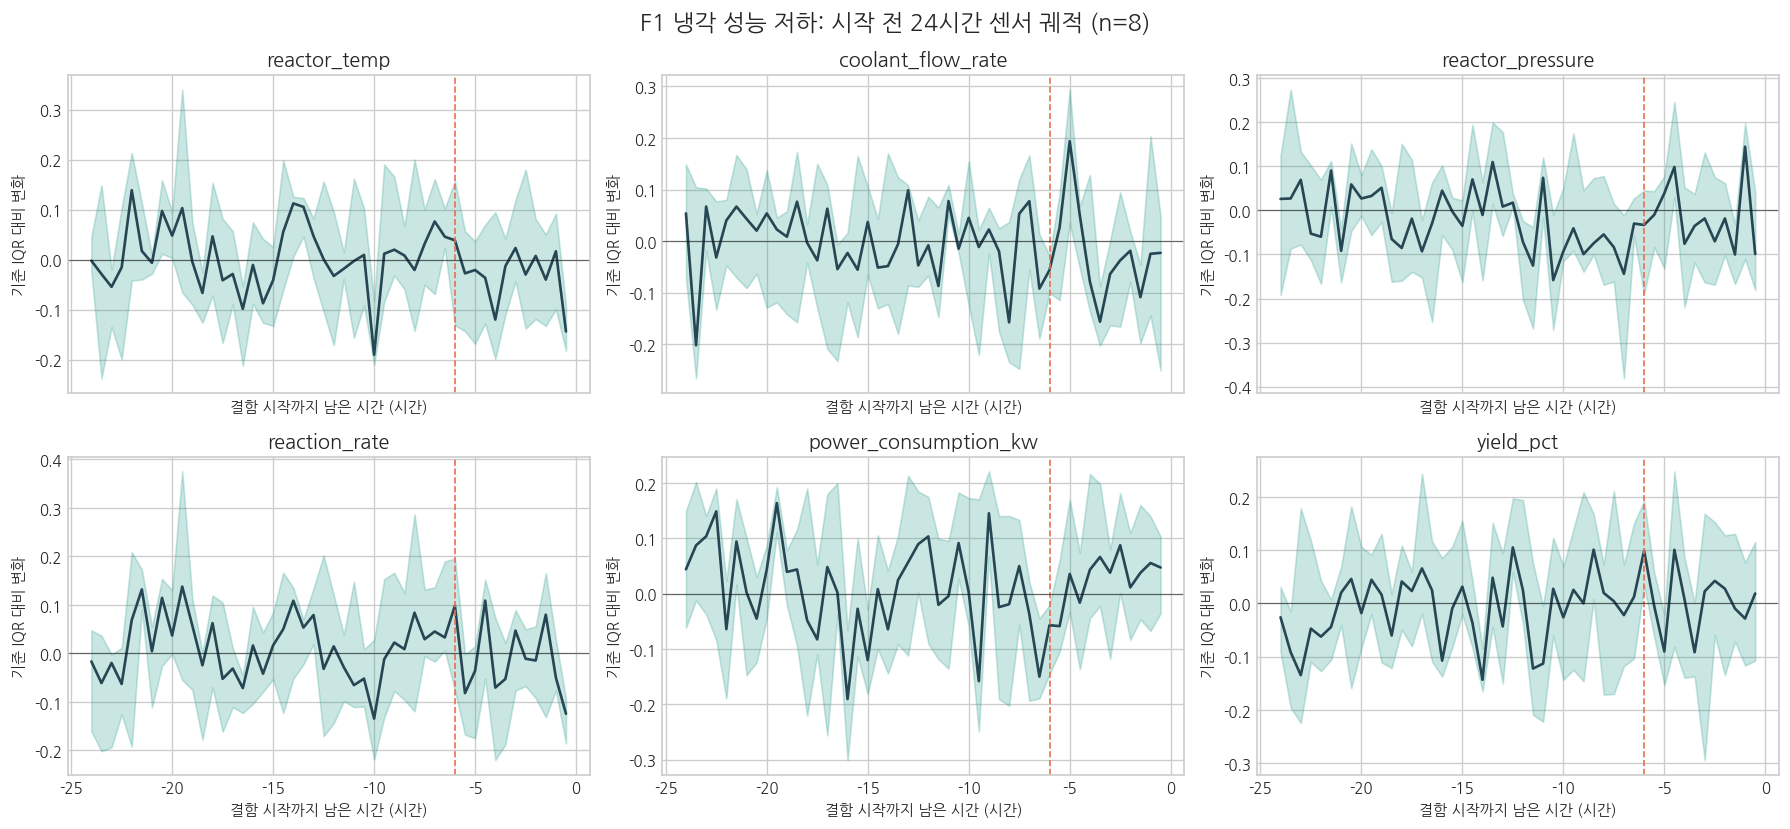

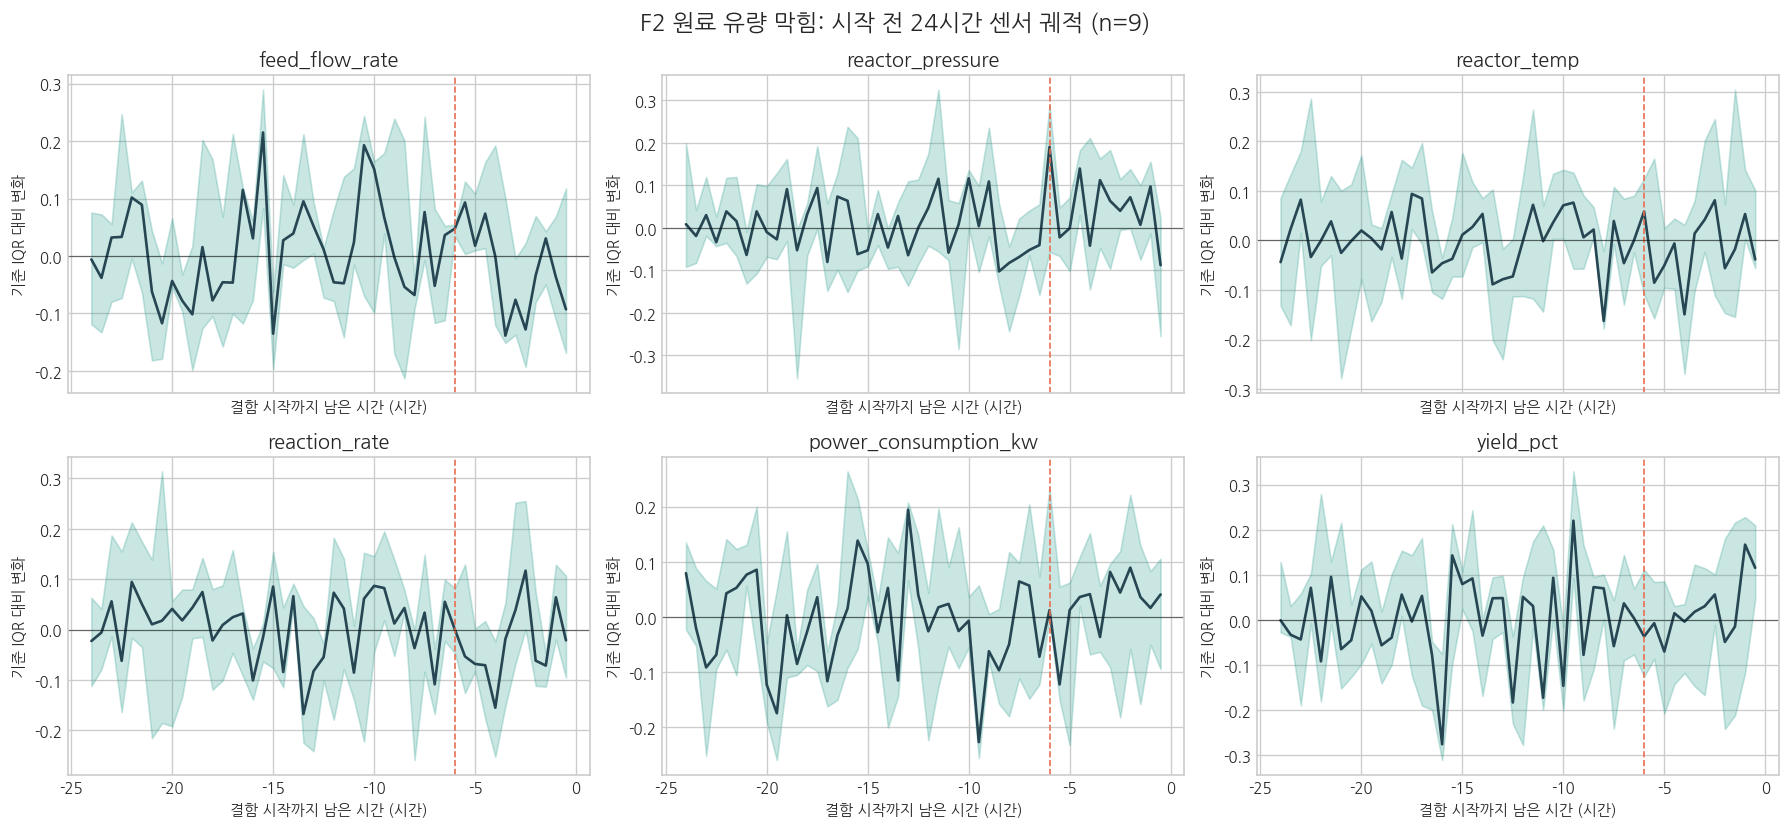

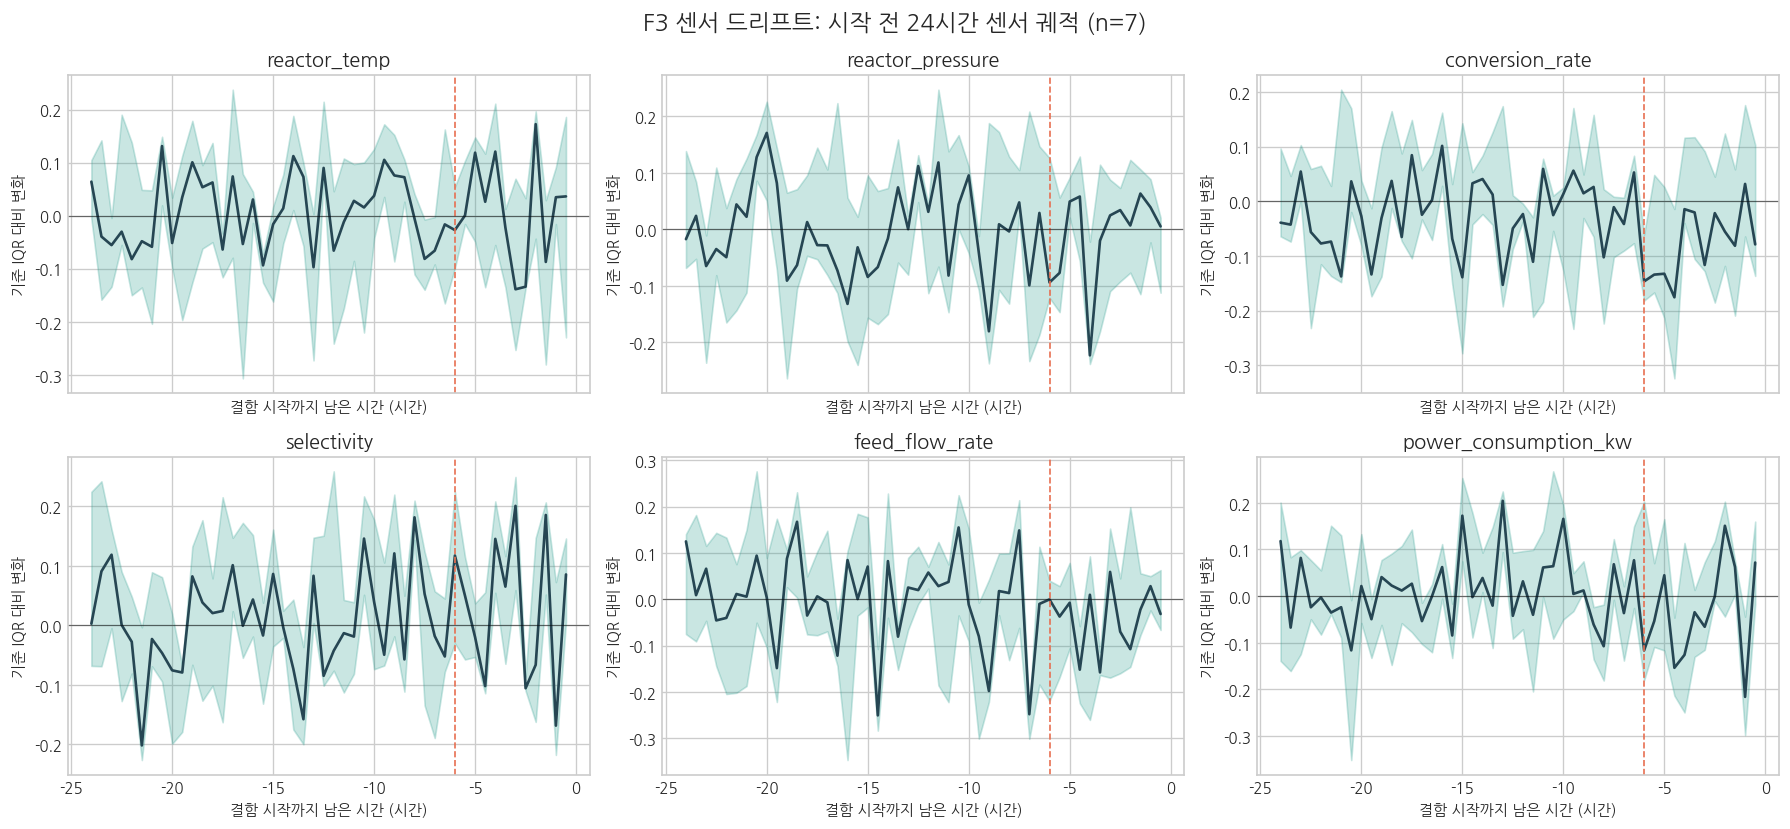

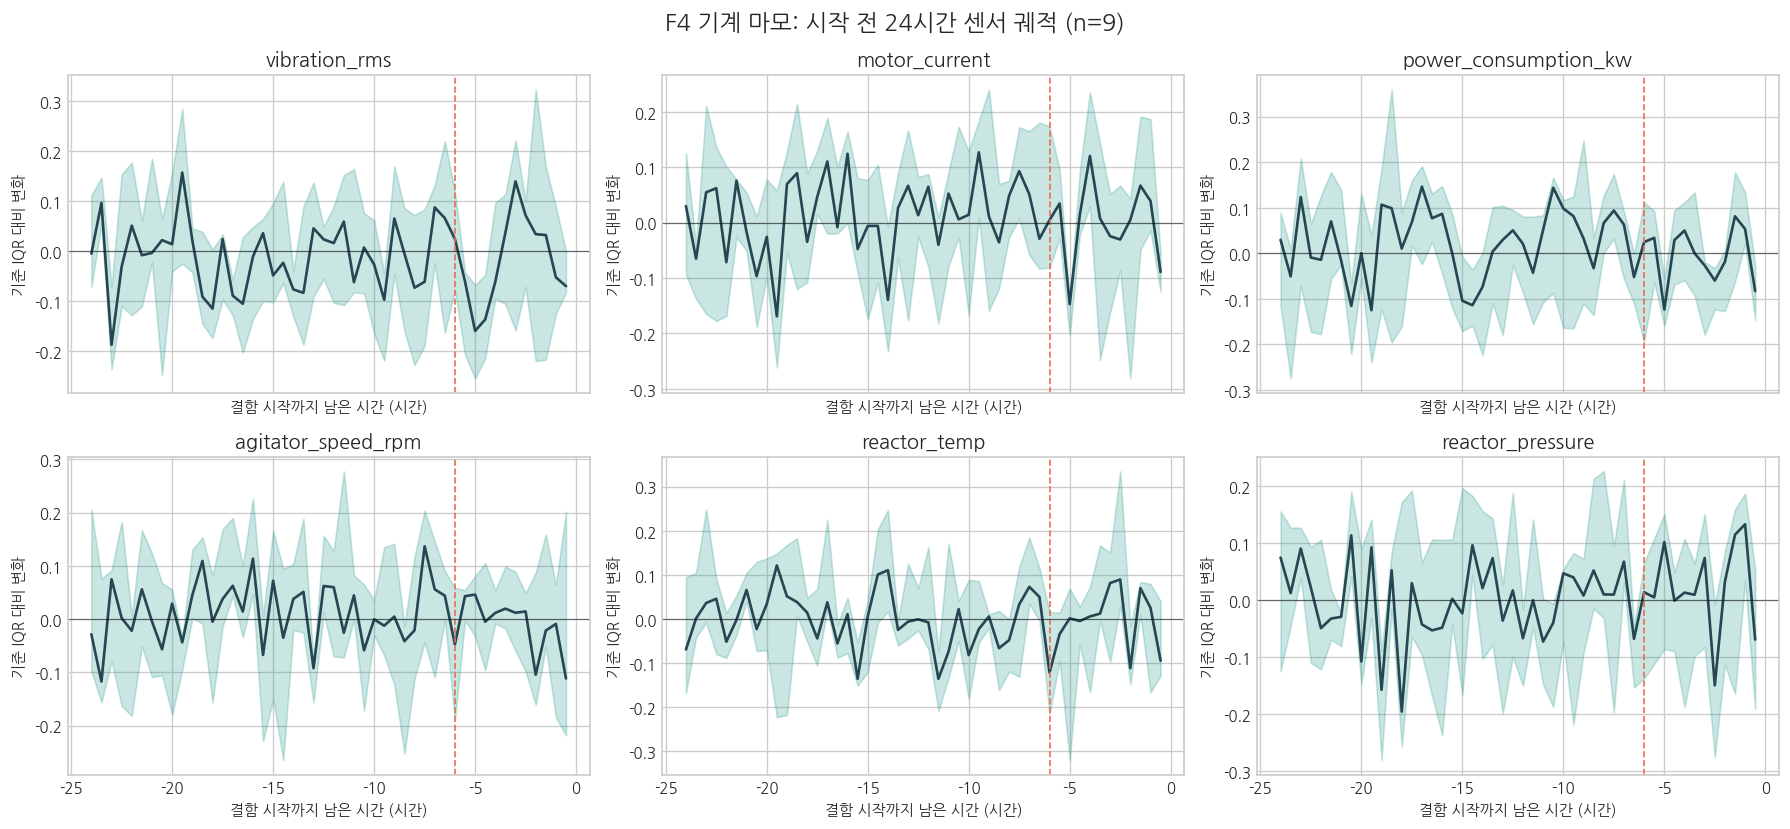

In [4]:
plot_sensors = {
    1: ["reactor_temp", "coolant_flow_rate", "reactor_pressure", "reaction_rate", "power_consumption_kw", "yield_pct"],
    2: ["feed_flow_rate", "reactor_pressure", "reactor_temp", "reaction_rate", "power_consumption_kw", "yield_pct"],
    3: ["reactor_temp", "reactor_pressure", "conversion_rate", "selectivity", "feed_flow_rate", "power_consumption_kw"],
    4: ["vibration_rms", "motor_current", "power_consumption_kw", "agitator_speed_rpm", "reactor_temp", "reactor_pressure"],
}

pre_windows["relative_30min"] = (np.floor(pre_windows["relative_min"] / 30) * 30).astype(int)

for fault_type, columns in plot_sensors.items():
    subset = pre_windows[pre_windows["event_fault_type"].eq(fault_type)]
    fig, axes = plt.subplots(2, 3, figsize=(15, 7), sharex=True)
    for ax, col in zip(axes.flat, columns):
        per_event = (subset.groupby(["event_id", "relative_30min"])[f"{col}__norm"]
                     .median().reset_index())
        summary = per_event.groupby("relative_30min")[f"{col}__norm"].agg(
            median="median", q25=lambda s: s.quantile(.25), q75=lambda s: s.quantile(.75)
        )
        x = summary.index.to_numpy() / 60
        ax.plot(x, summary["median"], color="#264653", linewidth=1.6)
        ax.fill_between(x, summary["q25"], summary["q75"], color="#2a9d8f", alpha=.25)
        ax.axvline(-6, color="#e76f51", linestyle="--", linewidth=1)
        ax.axhline(0, color="black", linewidth=.7, alpha=.5)
        ax.set_title(col)
        ax.set_ylabel("기준 IQR 대비 변화")
        ax.set_xlabel("결함 시작까지 남은 시간 (시간)")
    fig.suptitle(f"{fault_names[fault_type]}: 시작 전 24시간 센서 궤적 (n={subset['event_id'].nunique()})", fontsize=14)
    plt.tight_layout()
    plt.show()


## 4. 최근 6시간의 수준·변동성·추세

그래프의 미세한 차이를 수치로 요약합니다.

- **수준 변화:** 최근 6시간 중앙값과 기준 구간 중앙값의 차이 ÷ 기준 IQR
- **변동성 비율:** 최근 6시간의 60분 이동표준편차 중앙값 ÷ 기준 구간의 이동표준편차 중앙값
- **6시간 추세:** 최근 6시간 60분 이동평균의 시간당 기울기 ÷ 기준 IQR

이동 통계는 현재와 과거 59분만 사용합니다. 미래 관측값은 포함하지 않습니다.


결함 유형별 최근 6시간 수준 변화
sensor      agitator_speed_rpm  conversion_rate  coolant_flow_rate  feed_flow_rate  motor_current  power_consumption_kw  reaction_rate  reactor_pressure  reactor_temp  selectivity  vibration_rms  yield_pct
fault_type                                                                                                                                                                                                   
1                        0.033           -0.011             -0.046           0.006          0.027                 0.034         -0.035            -0.011        -0.038        0.025          0.044      0.040
2                        0.008           -0.037              0.010           0.015         -0.023                -0.000          0.004             0.030         0.014       -0.013         -0.015      0.007
3                        0.006           -0.067              0.063          -0.058          0.013                -0.039          0.000             0.016    

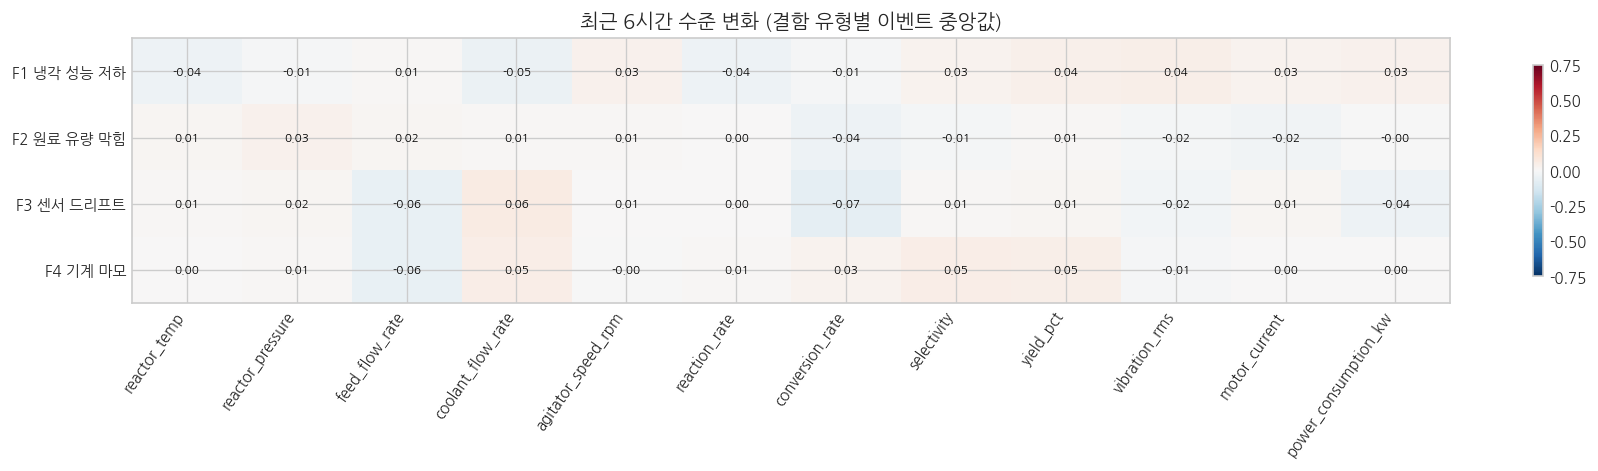

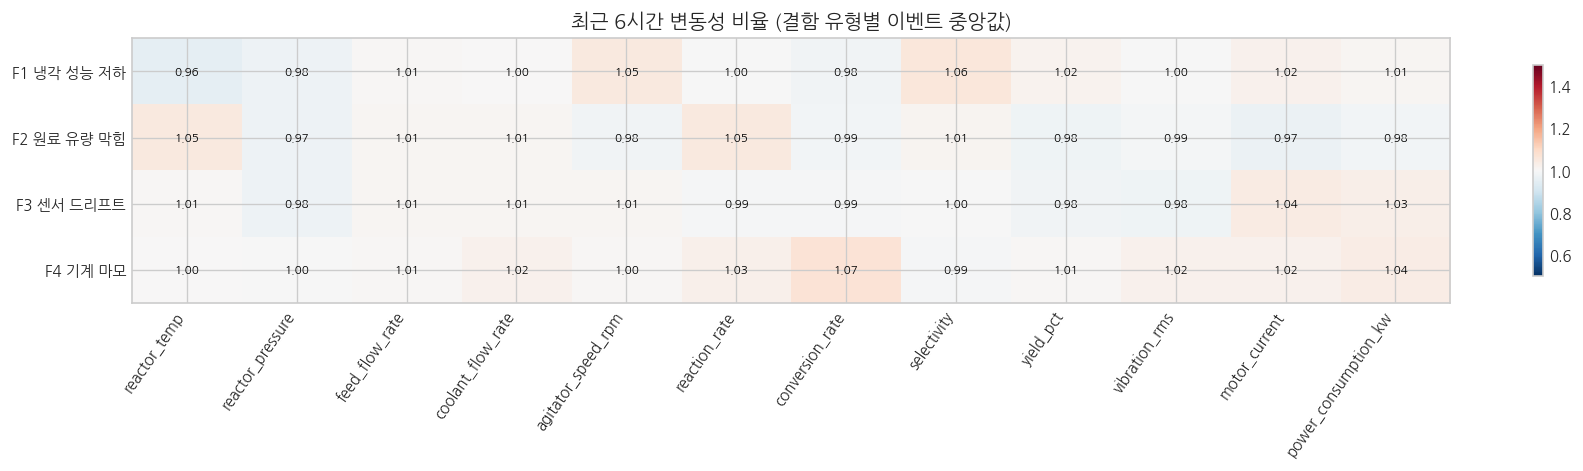

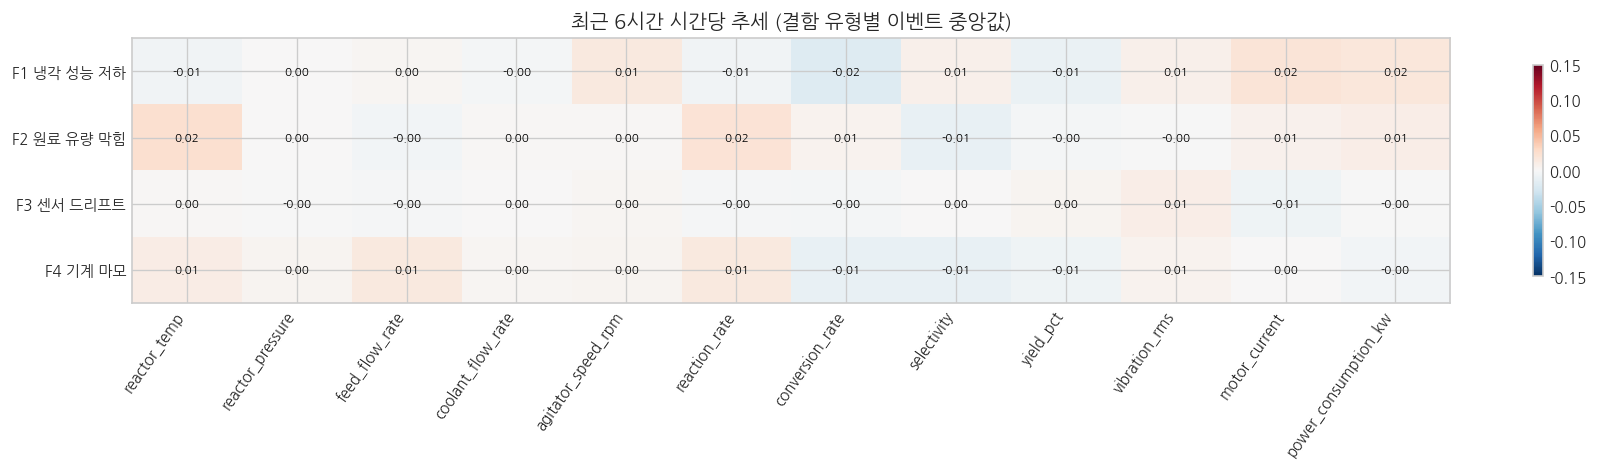

In [5]:
feature_rows = []

for event_id, g in pre_windows.groupby("event_id", sort=False):
    g = g.sort_values("relative_min").copy()
    fault_type = int(g["event_fault_type"].iloc[0])
    base_mask = g["relative_min"].lt(-720)
    recent_mask = g["relative_min"].ge(-360)

    for col in sensor_cols:
        base = g.loc[base_mask, col]
        recent = g.loc[recent_mask, col]
        base_iqr = base.quantile(.75) - base.quantile(.25)

        rolling_mean = g[col].rolling(60, min_periods=30).mean()
        rolling_std = g[col].rolling(60, min_periods=30).std()
        base_roll_std = rolling_std[base_mask].median()
        recent_roll_std = rolling_std[recent_mask].median()

        x_hours = g.loc[recent_mask, "relative_min"].to_numpy() / 60
        y = rolling_mean[recent_mask].to_numpy()
        valid = np.isfinite(x_hours) & np.isfinite(y)
        slope = np.polyfit(x_hours[valid], y[valid], 1)[0] if valid.sum() >= 2 else np.nan

        feature_rows.append({
            "event_id": event_id, "fault_type": fault_type, "sensor": col,
            "level_shift_iqr": (recent.median() - base.median()) / base_iqr if base_iqr else np.nan,
            "volatility_ratio": recent_roll_std / base_roll_std if base_roll_std else np.nan,
            "slope_iqr_per_hour": slope / base_iqr if base_iqr else np.nan,
        })

event_features = pd.DataFrame(feature_rows)
feature_medians = event_features.groupby(["fault_type", "sensor"])[
    ["level_shift_iqr", "volatility_ratio", "slope_iqr_per_hour"]
].median()

for metric, title, vmin, vmax, cmap in [
    ("level_shift_iqr", "최근 6시간 수준 변화", -.75, .75, "RdBu_r"),
    ("volatility_ratio", "최근 6시간 변동성 비율", .5, 1.5, "RdBu_r"),
    ("slope_iqr_per_hour", "최근 6시간 시간당 추세", -.15, .15, "RdBu_r"),
]:
    matrix = feature_medians[metric].unstack("sensor").reindex(index=[1, 2, 3, 4], columns=sensor_cols)
    fig, ax = plt.subplots(figsize=(15, 4))
    im = ax.imshow(matrix, aspect="auto", cmap=cmap, vmin=vmin, vmax=vmax)
    ax.set_yticks(range(4), [fault_names[i] for i in [1, 2, 3, 4]])
    ax.set_xticks(range(len(sensor_cols)), sensor_cols, rotation=55, ha="right")
    ax.set_title(title + " (결함 유형별 이벤트 중앙값)")
    for i in range(matrix.shape[0]):
        for j in range(matrix.shape[1]):
            value = matrix.iloc[i, j]
            ax.text(j, i, f"{value:.2f}", ha="center", va="center", fontsize=7,
                    color="white" if abs(value - (1 if metric == 'volatility_ratio' else 0)) > .35 else "black")
    fig.colorbar(im, ax=ax, shrink=.8)
    plt.tight_layout()
    plt.show()

print("결함 유형별 최근 6시간 수준 변화")
print(feature_medians["level_shift_iqr"].unstack("sensor").round(3).to_string())


## 5. 이벤트 간 일관성 확인

중앙값만 보면 일부 큰 이벤트가 전체 패턴처럼 보일 수 있습니다. 각 결함 유형에서 수준 변화의 방향이 이벤트 간 얼마나 일치하는지 확인합니다.

- `양의 변화 비율`이 0.5에 가까우면 상승과 하락이 섞여 있습니다.
- 0.8 이상 또는 0.2 이하이면 방향이 비교적 일관됩니다.
- 방향이 일치해도 변화 크기가 매우 작으면 실용적인 전조로 보기 어렵습니다.


결함 유형별 수준 변화 절댓값 상위 5개 센서
 fault_name               sensor  events  median_shift  positive_share  median_volatility  median_slope
F1 냉각 성능 저하    coolant_flow_rate       8        -0.046           0.250              1.003        -0.003
F1 냉각 성능 저하        vibration_rms       8         0.044           0.750              0.999         0.008
F1 냉각 성능 저하            yield_pct       8         0.040           0.625              1.018        -0.010
F1 냉각 성능 저하         reactor_temp       8        -0.038           0.375              0.956        -0.005
F1 냉각 성능 저하        reaction_rate       8        -0.035           0.375              0.998        -0.005
F2 원료 유량 막힘      conversion_rate       9        -0.037           0.444              0.988         0.005
F2 원료 유량 막힘     reactor_pressure       9         0.030           0.667              0.974         0.001
F2 원료 유량 막힘        motor_current       9        -0.023           0.333              0.972         0.006
F2 원료 유량 막힘        vibration_rms      

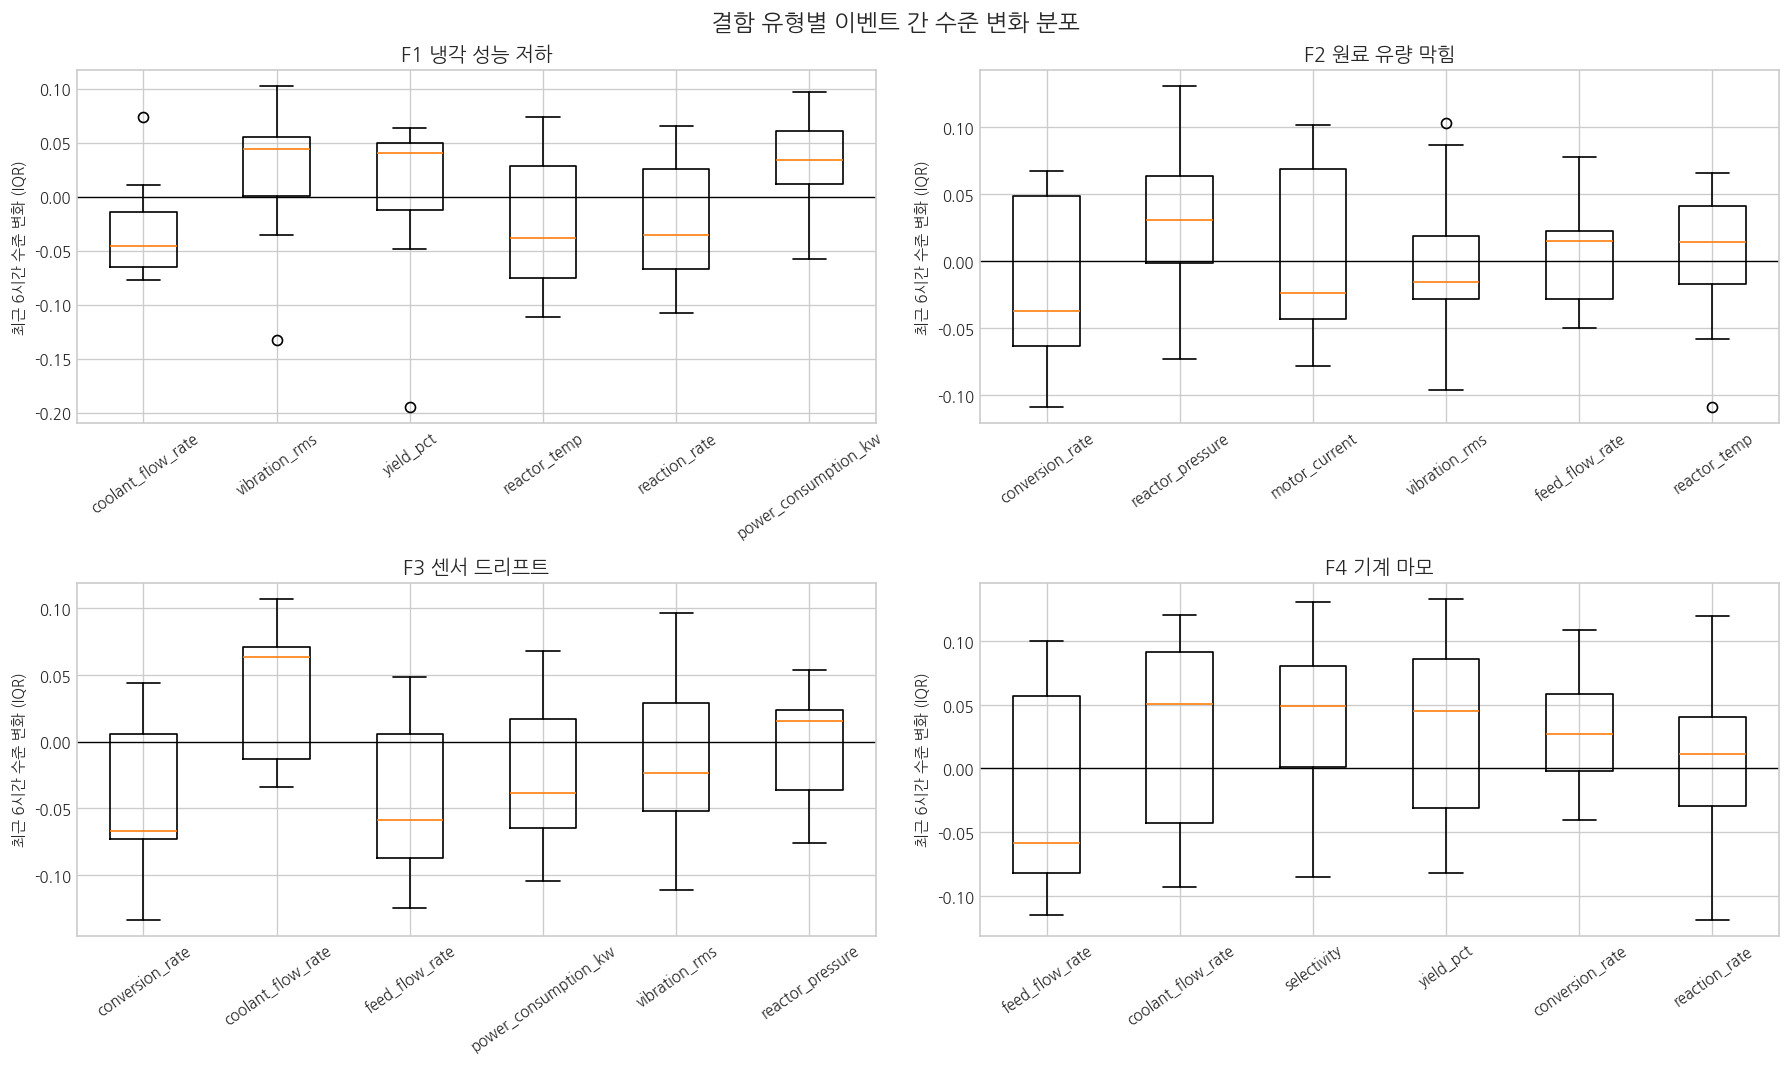

In [6]:
consistency = (event_features.assign(positive=lambda x: x["level_shift_iqr"].gt(0))
               .groupby(["fault_type", "sensor"])
               .agg(events=("event_id", "count"),
                    median_shift=("level_shift_iqr", "median"),
                    positive_share=("positive", "mean"),
                    median_volatility=("volatility_ratio", "median"),
                    median_slope=("slope_iqr_per_hour", "median"))
               .reset_index())

top_rows = []
for fault_type in [1, 2, 3, 4]:
    part = consistency[consistency["fault_type"].eq(fault_type)].copy()
    part["abs_shift"] = part["median_shift"].abs()
    part = part.nlargest(5, "abs_shift")
    part.insert(1, "fault_name", fault_names[fault_type])
    top_rows.append(part)
top_patterns = pd.concat(top_rows, ignore_index=True)
print("결함 유형별 수준 변화 절댓값 상위 5개 센서")
print(top_patterns[[
    "fault_name", "sensor", "events", "median_shift", "positive_share",
    "median_volatility", "median_slope"
]].round(3).to_string(index=False))

strong_level = consistency["median_shift"].abs().ge(.5).sum()
strong_volatility = (consistency["median_volatility"].sub(1).abs().ge(.5)).sum()
consistent_direction = (consistency["positive_share"].ge(.8) | consistency["positive_share"].le(.2)).sum()
print(f"\n|수준 변화| >= 0.5 IQR인 결함-센서 조합: {strong_level} / {len(consistency)}")
print(f"변동성이 1.5배 이상 또는 0.5배 이하인 조합: {strong_volatility} / {len(consistency)}")
print(f"변화 방향이 80% 이상 일치하는 조합: {consistent_direction} / {len(consistency)}")

fig, axes = plt.subplots(2, 2, figsize=(15, 9))
for ax, fault_type in zip(axes.flat, [1, 2, 3, 4]):
    part = event_features[event_features["fault_type"].eq(fault_type)]
    ordered_sensors = (part.groupby("sensor")["level_shift_iqr"].median()
                       .sort_values(key=lambda s: s.abs(), ascending=False).index[:6])
    values = [part.loc[part["sensor"].eq(sensor), "level_shift_iqr"].dropna() for sensor in ordered_sensors]
    ax.boxplot(values, tick_labels=ordered_sensors, showfliers=True)
    ax.axhline(0, color="black", linewidth=.8)
    ax.set_title(fault_names[fault_type])
    ax.set_ylabel("최근 6시간 수준 변화 (IQR)")
    ax.tick_params(axis="x", rotation=35)
plt.suptitle("결함 유형별 이벤트 간 수준 변화 분포", fontsize=14)
plt.tight_layout()
plt.show()


## 6. 해석과 모델링 시사점

이 데이터에서 결함 시작 전 24시간의 센서 변화는 전반적으로 작고, 같은 결함 유형 안에서도 방향이 섞여 있습니다. 최근 6시간의 결함 유형별 중앙 수준 변화도 대부분 기준 구간의 0.1 IQR 이내입니다. 강한 변동성 증가나 일관된 기울기도 제한적입니다.

따라서 현재 레이블 정의에서 결함이 시작되기 6~24시간 전에 뚜렷한 전조가 존재한다고 단정하기 어렵습니다. 합성 데이터 생성 규칙이 결함 시작 시점부터 센서 효과를 적용했을 가능성이 있습니다.

### 결함 유형별 관찰

- **F1 냉각 성능 저하:** 시작 전 냉각수 유량·온도·반응률 변화가 매우 작고 이벤트 간 방향이 일정하지 않습니다.
- **F2 원료 유량 막힘:** 시작 전 원료 유량의 뚜렷하고 반복적인 감소가 확인되지 않습니다.
- **F3 센서 드리프트:** 일부 센서의 미세한 변화가 있으나 이벤트 수가 7개로 적고 방향 일관성이 약합니다.
- **F4 기계 마모:** 시작 전 진동·모터 전류·전력의 뚜렷한 상승이 확인되지 않습니다.

### 모델링에 미치는 영향

1. `fault_type`이 0에서 결함으로 바뀌기 전을 예측하는 조기경보 모델은 이 데이터에서 학습 신호가 부족할 수 있습니다.
2. 결함 시작 이후 빠르게 감지하는 이상 탐지·결함 분류 문제는 별도로 가능성이 있습니다.
3. 조기경보가 목적이라면 결함 시작 전부터 서서히 변화하도록 합성 데이터 생성 규칙이나 레이블 정의를 수정해야 할 수 있습니다.
4. 이벤트 수가 33개로 적으므로 행 단위 통계보다 이벤트 단위 검증과 부트스트랩 신뢰구간을 사용해야 합니다.

이 결과는 “전조가 절대 없다”는 증명이 아닙니다. 현재 33개 이벤트와 6~24시간 구간에서 크고 반복적인 단변량 패턴이 관찰되지 않았다는 의미입니다.
